In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **GitHub code creator**

In [ ]:
!git config --global user.email "semanurkucuk7997@gmail.com"
!git config --global user.name "Semanur97"

In [ ]:
!ls /content

sample_data


In [ ]:
code = """
# buraya kodun gelecek
"""
with open("sam3_finetune.py", "w") as f:
    f.write(code)

In [ ]:
%cd /content/Sam3_Usage
!git status

/content/Sam3_Usage
On branch main

No commits yet

nothing to commit (create/copy files and use "git add" to track)


In [ ]:
%cd /content/Sam3_Usage

code = """
#hello world
"""
with open("sam3_finetune.py", "w") as f:
    f.write(code)

!ls

/content/Sam3_Usage
sam3_finetune.py


In [ ]:
!git add .
!git commit -m "SAM3 fine-tuning kodu eklendi"
!git branch -M main
!git push origin main

[main (root-commit) 33902a3] SAM3 fine-tuning kodu eklendi
 1 file changed, 2 insertions(+)
 create mode 100644 sam3_finetune.py
Enumerating objects: 3, done.
Counting objects: 100% (3/3), done.
Writing objects: 100% (3/3), 250 bytes | 250.00 KiB/s, done.
Total 3 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/Semanur97/Sam3_Usage.git
 * [new branch]      main -> main


# **GitHub Notebook copy and push**

In [14]:
!cp "/content/drive/MyDrive/PhD/Sam3_trials.ipynb" /content/Sam3_Usage/

cp: cannot create regular file '/content/Sam3_Usage/': Not a directory


In [15]:
%cd /content/Sam3_Usage
!git add .
!git commit -m "Sam3_trials notebook eklendi"
!git push origin main

[Errno 2] No such file or directory: '/content/Sam3_Usage'
/content/drive/MyDrive/PhD
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).


# **Sam3 Mask Decoder Training**

In [3]:
!pip install -q git+https://github.com/huggingface/transformers.git accelerate datasets monai

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import torch
print(torch.cuda.get_device_name(0))

NVIDIA L4


In [5]:
from datasets import load_dataset

dataset = load_dataset("kowndinya23/Kvasir-SEG")
dataset = dataset["train"].train_test_split(test_size=0.1, seed=42)
train_ds = dataset["train"]
test_ds = dataset["test"]
print(train_ds[0])  # kolon isimlerini kontrol et: image / annotation vs.

README.md:   0%|          | 0.00/497 [00:00<?, ?B/s]

data/train-00000-of-00001-7a33e3aba9046b(…): reconstructing file:   0%|          |  0.00B / 36.7MB            

data/train-00000-of-00001-7a33e3aba9046b(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-4d65c2d29(…): reconstructing file:   0%|          |  0.00B / 8.00MB            

data/validation-00000-of-00001-4d65c2d29(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/880 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/120 [00:00<?, ? examples/s]

{'name': 'cju77g99iyxc00817zqi2ppor', 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=620x531 at 0x7C0478DF38C0>, 'annotation': <PIL.PngImagePlugin.PngImageFile image mode=L size=620x531 at 0x7C03001046E0>}


In [6]:
from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get('HFtoken')
login(token=hf_token)

In [7]:
from transformers import Sam3Model, Sam3Processor

model_id = "facebook/sam3"
model = Sam3Model.from_pretrained(model_id, device_map="auto", token=hf_token)
processor = Sam3Processor.from_pretrained(model_id, token=hf_token)

config.json:   0%|          | 0.00/25.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


tokenizer_config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.64M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/588 [00:00<?, ?B/s]

In [ ]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "GPU yok")

True
NVIDIA L4


In [ ]:
for name, param in model.named_parameters():
    if "mask_decoder" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Eğitilebilir parametre: {trainable:,} / Toplam: {total:,}")

Eğitilebilir parametre: 2,298,881 / Toplam: 840,376,374


In [ ]:
print(train_ds.features)
print(train_ds[0].keys())

{'name': Value('string'), 'image': Image(mode=None, decode=True), 'annotation': Image(mode=None, decode=True)}
dict_keys(['name', 'image', 'annotation'])


In [ ]:
from PIL import Image as PILImage
import numpy as np
import torch
from torch.utils.data import Dataset

class SAM3SegDataset(Dataset):
    def __init__(self, hf_dataset, processor, prompt_text="a polyp", mask_size=(1008, 1008)):
        self.dataset = hf_dataset
        self.processor = processor
        self.prompt_text = prompt_text
        self.mask_size = mask_size

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"].convert("RGB")
        mask = item["annotation"].convert("L")

        # Maskeyi pixel_values ile aynı boyuta getir
        mask = mask.resize(self.mask_size, resample=PILImage.NEAREST)
        mask_array = np.array(mask)
        binary_mask = (mask_array > 127).astype(np.float32)

        inputs = self.processor(
            images=image,
            text=self.prompt_text,
            return_tensors="pt"
        )

        inputs = {k: v.squeeze(0) for k, v in inputs.items()}
        inputs["ground_truth_mask"] = torch.tensor(binary_mask)

        return inputs

In [ ]:
train_dataset = SAM3SegDataset(train_ds, processor, prompt_text="a polyp")
test_dataset = SAM3SegDataset(test_ds, processor, prompt_text="a polyp")

def collate_fn(batch):
    keys = batch[0].keys()
    collated = {}
    for key in keys:
        collated[key] = torch.stack([item[key] for item in batch])
    return collated

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=2, shuffle=False, collate_fn=collate_fn)

batch = next(iter(train_loader))
for k, v in batch.items():
    print(k, v.shape if hasattr(v, "shape") else type(v))

pixel_values torch.Size([2, 3, 1008, 1008])
original_sizes torch.Size([2, 2])
input_ids torch.Size([2, 32])
attention_mask torch.Size([2, 32])
ground_truth_mask torch.Size([2, 1008, 1008])


In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CUDA available: True
Device: NVIDIA L4


In [ ]:
# Önce modelin parametre isimlerine göz atalım
for name, param in model.named_parameters():
    print(name)

vision_encoder.backbone.embeddings.position_embeddings
vision_encoder.backbone.embeddings.patch_embeddings.projection.weight
vision_encoder.backbone.layer_norm.weight
vision_encoder.backbone.layer_norm.bias
vision_encoder.backbone.layers.0.layer_norm1.weight
vision_encoder.backbone.layers.0.layer_norm1.bias
vision_encoder.backbone.layers.0.attention.q_proj.weight
vision_encoder.backbone.layers.0.attention.q_proj.bias
vision_encoder.backbone.layers.0.attention.k_proj.weight
vision_encoder.backbone.layers.0.attention.k_proj.bias
vision_encoder.backbone.layers.0.attention.v_proj.weight
vision_encoder.backbone.layers.0.attention.v_proj.bias
vision_encoder.backbone.layers.0.attention.o_proj.weight
vision_encoder.backbone.layers.0.attention.o_proj.bias
vision_encoder.backbone.layers.0.layer_norm2.weight
vision_encoder.backbone.layers.0.layer_norm2.bias
vision_encoder.backbone.layers.0.mlp.fc1.weight
vision_encoder.backbone.layers.0.mlp.fc1.bias
vision_encoder.backbone.layers.0.mlp.fc2.weight

In [ ]:
# Tüm parametreleri dondur
for name, param in model.named_parameters():
    param.requires_grad = False

# Sadece mask_decoder'ı eğitilebilir yap
trainable_params = 0
total_params = 0

for name, param in model.named_parameters():
    total_params += param.numel()
    if name.startswith("mask_decoder"):
        param.requires_grad = True
        trainable_params += param.numel()

print(f"Toplam parametre: {total_params:,}")
print(f"Eğitilebilir parametre (mask_decoder): {trainable_params:,}")
print(f"Oran: {100 * trainable_params / total_params:.2f}%")

Toplam parametre: 840,376,374
Eğitilebilir parametre (mask_decoder): 2,298,881
Oran: 0.27%


In [ ]:
import torch

print(f"CUDA kullanılabilir mi: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU adı: {torch.cuda.get_device_name(0)}")
    print(f"GPU sayısı: {torch.cuda.device_count()}")
    print(f"Mevcut cihaz: {torch.cuda.current_device()}")
    print(f"Toplam bellek: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("UYARI: GPU bulunamadı! Colab'da Runtime > Change runtime type > GPU seçili mi kontrol et.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(f"Model cihaza taşındı: {device}")

CUDA kullanılabilir mi: True
GPU adı: NVIDIA L4
GPU sayısı: 1
Mevcut cihaz: 0
Toplam bellek: 23.66 GB
Model cihaza taşındı: cuda


In [9]:
# Kaggle API kurulumu
!pip install -q kaggle

# kaggle.json dosyasını Colab'a yükle (Kaggle hesabından "Create New API Token" ile alınır)
from google.colab import files
files.upload()  # kaggle.json seç

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d debeshjha1/kvasirseg -p /content/
!unzip -q /content/kvasirseg.zip -d /content/kvasir-seg
!ls /content/kvasir-seg

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/debeshjha1/kvasirseg
License(s): copyright-authors
100% 144M/144M [00:09<00:00, 16.6MB/s]

Kvasir-SEG  README.md  train.txt  val.txt


In [10]:
import os

for root, dirs, files in os.walk("/content/kvasir-seg"):
    level = root.replace("/content/kvasir-seg", "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 3:
        for f in files[:3]:
            print(f"{indent}  {f}")

kvasir-seg/
  val.txt
  README.md
  train.txt
  Kvasir-SEG/
    Kvasir-SEG/
      1911.07069.pdf
      annotated_images/
      masks/
      bbox/
      images/


In [ ]:
import os

base_path = "/content/kvasir-seg/Kvasir-SEG/Kvasir-SEG"

images_dir = os.path.join(base_path, "images")
masks_dir = os.path.join(base_path, "masks")

print(f"Görüntü sayısı: {len(os.listdir(images_dir))}")
print(f"Mask sayısı: {len(os.listdir(masks_dir))}")
print("Örnek görüntü dosyaları:", os.listdir(images_dir)[:5])
print("Örnek mask dosyaları:", os.listdir(masks_dir)[:5])

Görüntü sayısı: 1000
Mask sayısı: 1000
Örnek görüntü dosyaları: ['ck2395w2mb4vu07480otsu6tw.jpg', 'cju8cattbsivm0818p446wgel.jpg', 'cju3v11mrgwwb0755u242ygye.jpg', 'cju5eq8c8ck690850vix98hv3.jpg', 'cju5k3j3uf6de0817hszzfr7n.jpg']
Örnek mask dosyaları: ['ck2395w2mb4vu07480otsu6tw.jpg', 'cju8cattbsivm0818p446wgel.jpg', 'cju3v11mrgwwb0755u242ygye.jpg', 'cju5eq8c8ck690850vix98hv3.jpg', 'cju5k3j3uf6de0817hszzfr7n.jpg']


In [ ]:
with open("/content/kvasir-seg/train.txt") as f:
    train_lines = f.read().splitlines()
with open("/content/kvasir-seg/val.txt") as f:
    val_lines = f.read().splitlines()

print("Train örnek sayısı:", len(train_lines))
print("Val örnek sayısı:", len(val_lines))
print("İlk 5 train satırı:", train_lines[:5])
print("İlk 5 val satırı:", val_lines[:5])

Train örnek sayısı: 880
Val örnek sayısı: 120
İlk 5 train satırı: ['cju0qkwl35piu0993l0dewei2', 'cju0qoxqj9q6s0835b43399p4', 'cju0qx73cjw570799j4n5cjze', 'cju0roawvklrq0799vmjorwfv', 'cju0rx1idathl0835detmsp84']
İlk 5 val satırı: ['cju0s690hkp960855tjuaqvv0', 'cju0sr5ghl0nd08789uzf1raf', 'cju0sxqiclckk08551ycbwhno', 'cju0t4oil7vzk099370nun5h9', 'cju0tl3uz8blh0993wxvn7ly3']


In [ ]:
import os
from PIL import Image
from torch.utils.data import Dataset

class KvasirSegDataset(Dataset):
    def __init__(self, split_file, images_dir, masks_dir, prompt="polyp", transform=None):
        with open(split_file) as f:
            self.ids = f.read().splitlines()
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.prompt = prompt
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        file_id = self.ids[idx]
        img_path = os.path.join(self.images_dir, file_id + ".jpg")
        mask_path = os.path.join(self.masks_dir, file_id + ".jpg")

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")  # binary mask tek kanal

        if self.transform:
            image, mask = self.transform(image, mask)

        return {
            "image": image,
            "mask": mask,
            "prompt": self.prompt,
            "id": file_id,
        }

In [ ]:
base_path = "/content/kvasir-seg/Kvasir-SEG/Kvasir-SEG"
images_dir = os.path.join(base_path, "images")
masks_dir = os.path.join(base_path, "masks")

train_dataset = KvasirSegDataset(
    split_file="/content/kvasir-seg/train.txt",
    images_dir=images_dir,
    masks_dir=masks_dir,
    prompt="polyp",
)

val_dataset = KvasirSegDataset(
    split_file="/content/kvasir-seg/val.txt",
    images_dir=images_dir,
    masks_dir=masks_dir,
    prompt="polyp",
)

print(len(train_dataset), len(val_dataset))
sample = train_dataset[0]
print(sample["id"], sample["image"].size, sample["mask"].size, sample["prompt"])

880 120
cju0qkwl35piu0993l0dewei2 (622, 529) (622, 529) polyp


In [ ]:
import torch
print("CUDA mevcut mu:", torch.cuda.is_available())
print("Cihaz:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

CUDA mevcut mu: True
Cihaz: NVIDIA L4


In [ ]:
from transformers import Sam3Model, Sam3Processor
import torch

model_id = "facebook/sam3"  # gerekirse doğru repo adını teyit edeceğiz

device = "cuda" if torch.cuda.is_available() else "cpu"

processor = Sam3Processor.from_pretrained(model_id)
model = Sam3Model.from_pretrained(model_id).to(device)

# Önce tüm parametreleri dondur
for param in model.parameters():
    param.requires_grad = False

# Sadece mask_decoder'ı eğitilebilir yap
trainable_params = 0
total_params = 0
for name, param in model.named_parameters():
    total_params += param.numel()
    if "mask_decoder" in name:
        param.requires_grad = True
        trainable_params += param.numel()

print(f"Toplam parametre: {total_params:,}")
print(f"Eğitilebilir parametre (mask_decoder): {trainable_params:,}")
print(f"Oran: {100 * trainable_params / total_params:.2f}%")

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

Toplam parametre: 840,376,374
Eğitilebilir parametre (mask_decoder): 2,298,881
Oran: 0.27%


In [ ]:
# Processor'ün beklediği girdi formatını incele
print(processor)

Sam3Processor:
- image_processor: Sam3ImageProcessor {
  "data_format": "channels_first",
  "do_convert_rgb": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_processor_type": "Sam3ImageProcessor",
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "mask_size": {
    "height": 288,
    "width": 288
  },
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "height": 1008,
    "width": 1008
  }
}

- tokenizer: CLIPTokenizer(name_or_path='facebook/sam3', vocab_size=49408, model_max_length=32, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|startoftext|>', 'eos_token': '<|endoftext|>', 'unk_token': '<|endoftext|>', 'pad_token': '<|endoftext|>'}, added_tokens_decoder={
	49406: AddedToken("<|startoftext|>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
	49407: AddedToken("<|endoftext|>", rstrip=False, lstrip=False, single_word=F

In [ ]:
sample = train_dataset[0]
image = sample["image"]
prompt = sample["prompt"]

inputs = processor(images=image, text=prompt, return_tensors="pt").to(device)
print(inputs.keys())
for k, v in inputs.items():
    if hasattr(v, "shape"):
        print(k, v.shape)
    else:
        print(k, type(v), v)

KeysView({'pixel_values': tensor([[[[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],

         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]],

         [[-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          ...,
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.],
          [-1., -1., -1.,  ..., -1., -1., -1.]]]], device='cuda:0'), 'original_sizes': tensor([[529, 622]], d

In [ ]:
import torch.nn.functional as F
import numpy as np

def collate_fn(batch):
    images = [item["image"] for item in batch]
    prompts = [item["prompt"] for item in batch]
    masks = [item["mask"] for item in batch]
    ids = [item["id"] for item in batch]

    inputs = processor(images=images, text=prompts, return_tensors="pt")

    target_size = inputs["pixel_values"].shape[-2:]
    processed_masks = []
    for mask in masks:
        mask_arr = np.array(mask, dtype=np.float32) / 255.0
        mask_tensor = torch.from_numpy(mask_arr).unsqueeze(0).unsqueeze(0)
        mask_resized = F.interpolate(mask_tensor, size=target_size, mode="nearest")
        processed_masks.append(mask_resized.squeeze(0))

    masks_tensor = torch.stack(processed_masks)

    return {
        "pixel_values": inputs["pixel_values"],
        "input_ids": inputs["input_ids"],
        "attention_mask": inputs["attention_mask"],
        "masks": masks_tensor,
        "ids": ids,
    }

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=2,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=2,
)

# Test
batch = next(iter(train_loader))
for k, v in batch.items():
    if hasattr(v, "shape"):
        print(k, v.shape)
    else:
        print(k, v)

pixel_values torch.Size([4, 3, 1008, 1008])
input_ids torch.Size([4, 32])
attention_mask torch.Size([4, 32])
masks torch.Size([4, 1, 1008, 1008])
ids ['cju1dnz61vfp40988e78bkjga', 'cju1g20bdwq6u0835e16xugcd', 'cju89y9h0puti0818i5yw29e6', 'cju412uwlkva50850d1ps1ww7']


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from transformers import Sam3Model, Sam3Processor
from tqdm import tqdm

# -------------------------------------------------
# 1) GPU kontrolü
# -------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:", device)
if torch.cuda.is_available():
    print("GPU adı:", torch.cuda.get_device_name(0))

# -------------------------------------------------
# 2) Model ve processor yükleme
# -------------------------------------------------
MODEL_ID = "facebook/sam3"

processor = Sam3Processor.from_pretrained(MODEL_ID)
model = Sam3Model.from_pretrained(MODEL_ID)
model.to(device)

# -------------------------------------------------
# 3) Sadece mask_decoder'ı eğitilebilir yap
# -------------------------------------------------
# Önce her şeyi dondur
for param in model.parameters():
    param.requires_grad = False

# mask_decoder'ı aç (model mimarisine göre isim değişebilir, aşağıda kontrol kodu var)
trainable_params = []
for name, param in model.named_parameters():
    if "mask_decoder" in name:
        param.requires_grad = True
        trainable_params.append(param)

print(f"Eğitilebilir parametre sayısı (tensor): {len(trainable_params)}")
total_trainable = sum(p.numel() for p in trainable_params)
total_params = sum(p.numel() for p in model.parameters())
print(f"Eğitilebilir parametre: {total_trainable:,} / Toplam: {total_params:,} "
      f"({100*total_trainable/total_params:.2f}%)")

# Eğer "mask_decoder" isimli parametre bulunamazsa, isimleri yazdırıp kontrol edin:
if total_trainable == 0:
    print("UYARI: 'mask_decoder' adında parametre bulunamadı. Model parametre isimlerini kontrol edin:")
    for name, _ in model.named_parameters():
        print(name)

# -------------------------------------------------
# 4) Loss fonksiyonu: Dice + BCE
# -------------------------------------------------
def dice_loss(pred, target, eps=1e-6):
    pred = torch.sigmoid(pred)
    pred = pred.flatten(1)
    target = target.flatten(1)
    intersection = (pred * target).sum(-1)
    union = pred.sum(-1) + target.sum(-1)
    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()

def combined_loss(pred_masks, gt_masks):
    # pred_masks ve gt_masks aynı boyutta olmalı: [B, 1, H, W]
    bce = F.binary_cross_entropy_with_logits(pred_masks, gt_masks)
    dice = dice_loss(pred_masks, gt_masks)
    return bce + dice

# -------------------------------------------------
# 5) Optimizer
# -------------------------------------------------
optimizer = AdamW(trainable_params, lr=1e-4, weight_decay=1e-4)

# -------------------------------------------------
# 6) Eğitim döngüsü
# -------------------------------------------------
EPOCHS = 10
scaler = torch.cuda.amp.GradScaler()  # mixed precision için

def train_one_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0.0

    for batch in tqdm(dataloader, desc="Train"):
        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        gt_masks = batch["masks"].to(device).float()  # [B, 1, H, W]

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = model(
                pixel_values=pixel_values,
                input_ids=input_ids,
                attention_mask=attention_mask,
            )
            # SAM3 çıktısında mask logit alanı modele göre değişebilir.
            # Genelde outputs.pred_masks veya outputs.masks şeklinde olur.
            pred_masks = outputs.pred_masks  # [B, num_masks, H, W] olabilir

            # Eğer birden fazla mask adayı dönüyorsa (SAM tarzı), en iyi/ilk maskeyi seçin:
            if pred_masks.dim() == 5:
                pred_masks = pred_masks[:, 0]  # ilk prompt
            if pred_masks.shape[1] > 1:
                pred_masks = pred_masks[:, 0:1]  # ilk mask adayı

            # Boyut eşitleme (gerekirse)
            if pred_masks.shape[-2:] != gt_masks.shape[-2:]:
                pred_masks = F.interpolate(
                    pred_masks, size=gt_masks.shape[-2:],
                    mode="bilinear", align_corners=False
                )

            loss = combined_loss(pred_masks, gt_masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()

    return total_loss / len(dataloader)


@torch.no_grad()
def validate(model, dataloader, device):
    model.eval()
    total_loss = 0.0
    for batch in tqdm(dataloader, desc="Val"):
        pixel_values = batch["pixel_values"].to(device)
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        gt_masks = batch["masks"].to(device).float()

        outputs = model(
            pixel_values=pixel_values,
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        pred_masks = outputs.pred_masks
        if pred_masks.dim() == 5:
            pred_masks = pred_masks[:, 0]
        if pred_masks.shape[1] > 1:
            pred_masks = pred_masks[:, 0:1]
        if pred_masks.shape[-2:] != gt_masks.shape[-2:]:
            pred_masks = F.interpolate(
                pred_masks, size=gt_masks.shape[-2:],
                mode="bilinear", align_corners=False
            )
        loss = combined_loss(pred_masks, gt_masks)
        total_loss += loss.item()

    return total_loss / len(dataloader)


# -------------------------------------------------
# 7) Eğitimi başlat
# -------------------------------------------------
best_val_loss = float("inf")

for epoch in range(EPOCHS):
    print(f"\n=== Epoch {epoch+1}/{EPOCHS} ===")
    train_loss = train_one_epoch(model, train_loader, optimizer, device)
    val_loss = validate(model, val_loader, device)
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "sam3_maskdecoder_best.pt")
        print("✅ En iyi model kaydedildi.")

print("Eğitim tamamlandı.")

Kullanılan cihaz: cuda
GPU adı: NVIDIA L4


Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

/tmp/ipykernel_559/2153366846.py:78: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()  # mixed precision için


Eğitilebilir parametre sayısı (tensor): 32
Eğitilebilir parametre: 2,298,881 / Toplam: 840,376,374 (0.27%)

=== Epoch 1/10 ===


Train:   0%|          | 0/220 [00:00<?, ?it/s]/tmp/ipykernel_559/2153366846.py:92: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val: 100%|██████████| 30/30 [01:48<00:00,  3.63s/it]


Train Loss: 0.7266 | Val Loss: 0.4971
✅ En iyi model kaydedildi.

=== Epoch 2/10 ===


... (14 outputs left out)

Val: 100%|██████████| 30/30 [01:48<00:00,  3.63s/it]


Train Loss: 0.2550 | Val Loss: 0.4298

=== Epoch 10/10 ===


Val: 100%|██████████| 30/30 [01:48<00:00,  3.62s/it]


Train Loss: 0.2487 | Val Loss: 0.3744
✅ En iyi model kaydedildi.
Eğitim tamamlandı.


In [ ]:
import shutil
import os

# Kaynak dosya yolu
kaynak = '/content/Sam3_Usage/sam3_maskdecoder_best.pt'

# Kopyalamak istediğiniz Drive klasörünün yolunu buraya yazın:
# Örneğin: '/content/drive/MyDrive/Model_Yedekleri'
hedef_klasor = '/content/drive/MyDrive/PhD'

# Klasör yoksa otomatik oluşturur
os.makedirs(hedef_klasor, exist_ok=True)

# Kopyalama işlemini gerçekleştirir
hedef_dosya = os.path.join(hedef_klasor, 'sam3_maskdecoder_best.pt')
shutil.copy(kaynak, hedef_dosya)

print(f"Kopyalama tamamlandı: {hedef_dosya}")

Kopyalama tamamlandı: /content/drive/MyDrive/PhD/sam3_maskdecoder_best.pt


In [ ]:
!git rm --cached sam3_maskdecoder_best.pt
!git rm --cached kvasir-seg.zip

rm 'sam3_maskdecoder_best.pt'
rm 'kvasir-seg.zip'


In [18]:
# token kaldirildi


fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
[Errno 2] No such file or directory: '/content/Sam3_Usage'
/content/drive/MyDrive/PhD
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).
fatal: not a git repository (or any parent up to mount point /content)
Stopping at filesystem boundary (GIT_DISCOVERY_ACROSS_FILESYSTEM not set).


# **Evaluation**

✅ Val dataset yüklendi: 120 örnek


Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

✅ Fine-tuned model yüklendi.


Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

✅ Base model yüklendi.
Base model:
  pred_masks shape: torch.Size([1, 200, 288, 288])
Fine-tuned model:
  pred_masks shape: torch.Size([1, 200, 288, 288])

Base Model IoU : 0.0000
Fine-tuned IoU : 0.8166


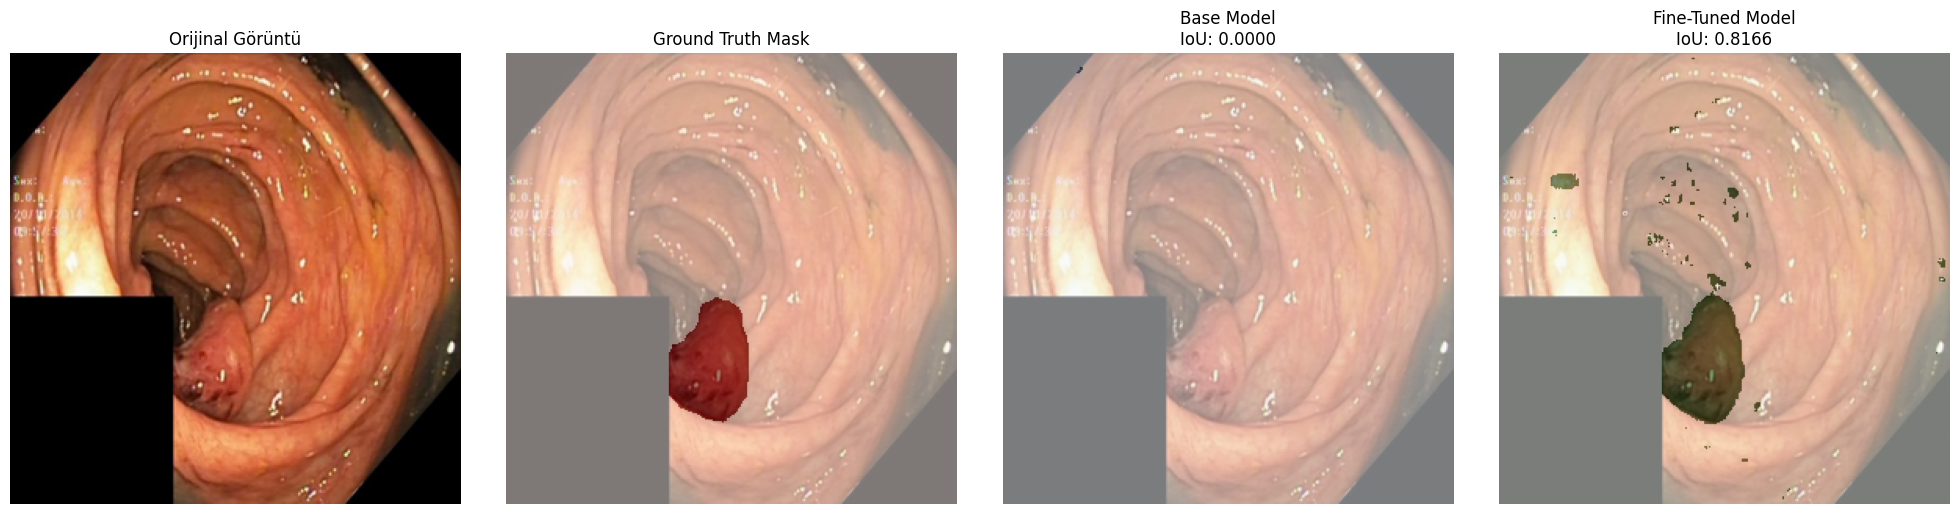

✅ Görsel kaydedildi: comparison.png


In [11]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import os
from PIL import Image as PILImage
from torch.utils.data import Dataset
from transformers import Sam3Model, Sam3Processor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -------------------------------------------------
# 1) Dataset sınıfını tanımla
# -------------------------------------------------
class KvasirSegDataset(Dataset):
    def __init__(self, split_file, images_dir, masks_dir, prompt="polyp"):
        with open(split_file) as f:
            self.ids = f.read().splitlines()
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.prompt = prompt

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        file_id = self.ids[idx]
        image = PILImage.open(os.path.join(self.images_dir, file_id + ".jpg")).convert("RGB")
        mask  = PILImage.open(os.path.join(self.masks_dir,  file_id + ".jpg")).convert("L")
        return {"image": image, "mask": mask, "prompt": self.prompt, "id": file_id}

# -------------------------------------------------
# 2) Dataset'i yükle
# -------------------------------------------------
base_path  = "/content/kvasir-seg/Kvasir-SEG/Kvasir-SEG"
images_dir = os.path.join(base_path, "images")
masks_dir  = os.path.join(base_path, "masks")

val_dataset = KvasirSegDataset(
    split_file="/content/kvasir-seg/val.txt",
    images_dir=images_dir,
    masks_dir=masks_dir,
    prompt="polyp",
)
print(f"✅ Val dataset yüklendi: {len(val_dataset)} örnek")

# -------------------------------------------------
# 3) Processor ve modelleri yükle
# -------------------------------------------------
MODEL_ID  = "facebook/sam3"
processor = Sam3Processor.from_pretrained(MODEL_ID)

ft_model = Sam3Model.from_pretrained(MODEL_ID)
ft_model.load_state_dict(torch.load(
    "/content/drive/MyDrive/PhD/sam3_maskdecoder_best.pt", map_location=device))
ft_model.to(device).eval()
print("✅ Fine-tuned model yüklendi.")

base_model = Sam3Model.from_pretrained(MODEL_ID)
base_model.to(device).eval()
print("✅ Base model yüklendi.")

# -------------------------------------------------
# 4) Test örneği hazırla
# -------------------------------------------------
sample  = val_dataset[0]
image   = sample["image"]
mask_pil = sample["mask"]

inputs = processor(images=image, text="polyp", return_tensors="pt").to(device)

# -------------------------------------------------
# 5) Tahminleri al
# -------------------------------------------------
def get_best_mask(outputs):
    pred = outputs.pred_masks
    print(f"  pred_masks shape: {pred.shape}")
    # Boyutlara göre doğru dilimi al
    while pred.dim() > 2:
        pred = pred[0]
    return torch.sigmoid(pred).cpu().numpy()

with torch.no_grad():
    base_outputs = base_model(**inputs)
    ft_outputs   = ft_model(**inputs)

print("Base model:")
base_mask = get_best_mask(base_outputs)
print("Fine-tuned model:")
ft_mask   = get_best_mask(ft_outputs)

base_binary = (base_mask > 0.5).astype(np.uint8)
ft_binary   = (ft_mask   > 0.5).astype(np.uint8)

# -------------------------------------------------
# 6) IoU hesapla
# -------------------------------------------------
def iou(pred, gt):
    intersection = (pred & gt).sum()
    union        = (pred | gt).sum()
    return intersection / (union + 1e-6)

H, W = base_binary.shape
gt_resized = np.array(
    mask_pil.resize((W, H), PILImage.NEAREST).point(lambda x: 1 if x > 127 else 0)
)

base_iou = iou(base_binary, gt_resized)
ft_iou   = iou(ft_binary,   gt_resized)
print(f"\nBase Model IoU : {base_iou:.4f}")
print(f"Fine-tuned IoU : {ft_iou:.4f}")

# -------------------------------------------------
# 7) Görselleştir
# -------------------------------------------------
orig_vis = np.array(image.resize((W, H))) / 255.0
gt_vis   = gt_resized.astype(float)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(orig_vis)
axes[0].set_title("Orijinal Görüntü")
axes[0].axis("off")

axes[1].imshow(orig_vis)
axes[1].imshow(gt_vis, alpha=0.5, cmap="Reds")
axes[1].set_title("Ground Truth Mask")
axes[1].axis("off")

axes[2].imshow(orig_vis)
axes[2].imshow(base_binary.astype(float), alpha=0.5, cmap="Blues")
axes[2].set_title(f"Base Model\nIoU: {base_iou:.4f}")
axes[2].axis("off")

axes[3].imshow(orig_vis)
axes[3].imshow(ft_binary.astype(float), alpha=0.5, cmap="Greens")
axes[3].set_title(f"Fine-Tuned Model\nIoU: {ft_iou:.4f}")
axes[3].axis("off")

plt.tight_layout()
plt.savefig("comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Görsel kaydedildi: comparison.png")